# RLC Circuits and Signal Filtering with Differential Equations

**Course:** SENG 202 – Differential Equations (Level 200, Semester 2)
**Project type:** Course project – analytical and numerical study
**Tools:** Python 3, SymPy (symbolic solutions and Laplace transforms), NumPy, SciPy and Matplotlib – everything runs in Google Colab with no extra installation.

---

## 1. Project description

Every electronic device must deal with **changing signals**: a power supply switching on, a sensor reading drifting, a clock signal toggling, noise from the mains. Capacitors and inductors store energy, so voltages and currents in a circuit are governed by **differential equations**. In this project we analyse and design the signal chain of a sensor interface using every topic from SENG 202.

### Problem statement
An electronics team is designing the **front end of a sensor measurement system**. The sensor's signal travels along a long cable and is then cleaned by filters before it is digitised. The signal is weak and noisy. It is also contaminated by 50 Hz mains hum and by a square-wave clock signal from a nearby digital circuit. The team must answer these questions:

1. **Switching on:** When power is applied, how quickly does an RC filter settle, and how does it respond to a sine-wave input?
2. **Ringing:** Does an RLC filter overshoot and oscillate after a sudden change? How do the component values decide this, and when does resonance occur?
3. **Pulses and switches:** How does the circuit respond to pulses, switching events and sudden impulses?
4. **Multi-stage filters:** How do coupled stages behave, and why do two stages filter better than one?
5. **Changing components:** How does a circuit behave when a component, such as a capacitive sensor, changes value over time?
6. **Periodic interference:** What frequencies does a square-wave clock contain, and can a tuned circuit pick one of them out?
7. **Noise removal:** How can the useful signal be separated from mains hum and random noise?
8. **The cable:** How much voltage reaches the far end of a long leaky cable? How long does a signal take to travel along a long wire, and how do pulses reflect on a transmission line?

The task is to model each part of the system with a differential equation and solve it exactly where possible. Each exact answer is checked against a numerical solution, and the results are used to explain the design.

### Objectives
1. Solve **first-order ODEs** (integrating factor) for RC circuits.
2. Solve **second-order ODEs** (characteristic equation, undetermined coefficients) for RLC circuits, including damping and resonance.
3. Solve **initial-value problems** symbolically and numerically.
4. Use **Laplace transforms** for switching, pulses, impulses, transfer functions and convolution.
5. Analyse **systems of differential equations** with eigenvalues and phase portraits.
6. Find a **series solution** for a circuit with a time-varying capacitor.
7. Use **Fourier series** to analyse square-wave interference and design a tuned filter.
8. Use the **Fourier transform** to analyse spectra and remove noise.
9. Solve **boundary-value problems** and **partial differential equations** (diffusion and wave equations) for cables and transmission lines.

### Course topics mapped to notebook sections

| # | Section | SENG 202 topics used |
|---|---|---|
| 2 | RC circuit | First-order linear ODEs, integrating factor, initial-value problems, existence and uniqueness |
| 3 | RLC circuit | Second-order ODEs, characteristic equation, over/critical/under damping, undetermined coefficients, resonance |
| 4 | Switching, pulses and impulses | Laplace transforms, partial fractions, inverse transforms, unit step and shifting, Dirac delta, transfer functions, poles, convolution |
| 5 | Multi-stage filters | Systems of ODEs, matrix form, eigenvalues, phase portraits |
| 6 | Time-varying capacitor | Series solutions about an ordinary point, recurrence for coefficients, Airy functions |
| 7 | Square-wave interference | Fourier series, Gibbs phenomenon, Parseval's identity, harmonic response |
| 8 | Noise removal | Fourier transforms, spectra, filtering, link between the Laplace and Fourier transforms |
| 9 | The cable | Boundary-value problems, PDEs (diffusion and wave equations), separation of variables, Fourier series solutions |
| 10 | Conclusion | Engineering summary |

### How to run
Open this notebook in Google Colab and choose **Runtime → Run all**. Each section defines its own component values, so you can change them and re-run.

**A note on units:** Sections 3 and 4 use normalised values ($L = 1$ H, $C = 0.2$ F) so that the exact algebra stays clean. The same mathematics applies unchanged to real values in mH and µF, which the other sections use.

## 1. Setup

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp, trapezoid
from scipy.signal import lsim
from scipy.special import airy
from scipy.optimize import brentq
from IPython.display import display, Math

sp.init_printing()
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(202)          # fixed seed so results are repeatable

tt, s = sp.symbols("t s", positive=True)  # symbolic time and Laplace variable

def show(label, expr):
    display(Math(label + sp.latex(expr)))

## 2. The RC filter: first-order ODEs and initial-value problems

A resistor $R$ in series with a capacitor $C$ forms the simplest low-pass filter. Kirchhoff's voltage law gives the **first-order linear ODE**
$$RC\,\frac{dv}{dt} + v = v_{in}(t), \qquad v(0) = 0 .$$
Dividing by $RC$ gives the standard form $v' + \frac{1}{RC}v = \frac{v_{in}}{RC}$. The **integrating factor** is $\mu(t) = e^{t/RC}$, which gives
$$v(t) = e^{-t/RC}\int_0^t \frac{v_{in}(u)}{RC}\,e^{u/RC}\,du .$$
The coefficients are continuous, so the **existence and uniqueness theorem** guarantees exactly one solution for each initial value.

In [2]:
R, C, V, w = sp.symbols("R C V_0 omega", positive=True)
u = sp.symbols("u", positive=True)
v = sp.Function("v")

# Step input: v_in = V0 (switched on at t = 0)
ode_step = sp.Eq(R * C * v(tt).diff(tt) + v(tt), V)
sol_step = sp.dsolve(ode_step, v(tt), ics={v(0): 0})
show(r"\text{ODE: }", ode_step)
show(r"\text{Solution: }", sol_step)

# The same result by the integrating factor, step by step
mu = sp.exp(tt / (R * C))
by_hand = sp.integrate((mu * V / (R * C)).subs(tt, u), (u, 0, tt)) / mu
print("Integrating-factor result equals dsolve:", sp.simplify(by_hand - sol_step.rhs) == 0)

# Sinusoidal input: v_in = V0 sin(ωt)
ode_sin = sp.Eq(R * C * v(tt).diff(tt) + v(tt), V * sp.sin(w * tt))
sol_sin = sp.dsolve(ode_sin, v(tt), ics={v(0): 0})
show(r"\text{Sine input: } v(t) = ", sp.simplify(sol_sin.rhs))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Integrating-factor result equals dsolve: True


<IPython.core.display.Math object>

Time constant τ = RC = 1.00 ms
Max |exact - numerical|: step = 9.71e-10 V, sine = 4.76e-09 V
Steady state for the 200 Hz input: amplitude 3.113 V (gain 0.623), phase -51.5°


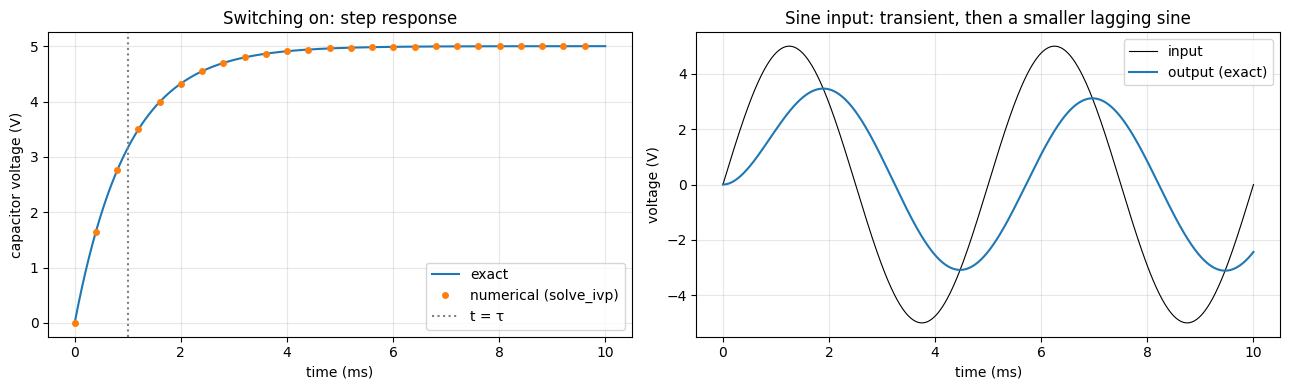

In [3]:
R_RC, C_RC, V0, F_SIN = 1e3, 1e-6, 5.0, 200.0
TAU = R_RC * C_RC
vals = {R: R_RC, C: C_RC, V: V0, w: 2 * np.pi * F_SIN}
v_step = sp.lambdify(tt, sol_step.rhs.subs(vals), "numpy")
v_sin = sp.lambdify(tt, sol_sin.rhs.subs(vals), "numpy")

t = np.linspace(0, 10e-3, 1000)
num_step = solve_ivp(lambda t_, y: (V0 - y) / TAU, (0, t[-1]), [0.0], t_eval=t, rtol=1e-9, atol=1e-12)
num_sin = solve_ivp(lambda t_, y: (V0 * np.sin(2 * np.pi * F_SIN * t_) - y) / TAU, (0, t[-1]), [0.0],
                    t_eval=t, rtol=1e-9, atol=1e-12)
print(f"Time constant τ = RC = {TAU*1e3:.2f} ms")
print(f"Max |exact - numerical|: step = {np.max(np.abs(v_step(t) - num_step.y[0])):.2e} V, "
      f"sine = {np.max(np.abs(v_sin(t) - num_sin.y[0])):.2e} V")

gain = 1 / np.sqrt(1 + (2 * np.pi * F_SIN * TAU) ** 2)
phase = -np.degrees(np.arctan(2 * np.pi * F_SIN * TAU))
print(f"Steady state for the {F_SIN:.0f} Hz input: amplitude {V0*gain:.3f} V (gain {gain:.3f}), phase {phase:.1f}°")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(1e3 * t, v_step(t), label="exact")
axs[0].plot(1e3 * t[::40], num_step.y[0][::40], "o", ms=4, label="numerical (solve_ivp)")
axs[0].axvline(1e3 * TAU, color="gray", ls=":", label="t = τ")
axs[0].set(xlabel="time (ms)", ylabel="capacitor voltage (V)", title="Switching on: step response")
axs[0].legend()
axs[1].plot(1e3 * t, V0 * np.sin(2 * np.pi * F_SIN * t), "k", lw=0.8, label="input")
axs[1].plot(1e3 * t, v_sin(t), label="output (exact)")
axs[1].set(xlabel="time (ms)", ylabel="voltage (V)", title="Sine input: transient, then a smaller lagging sine")
axs[1].legend()
plt.tight_layout()
plt.show()

## 3. The RLC circuit: second-order ODEs, damping and resonance

Adding an inductor gives a series RLC circuit. With charge $q$ on the capacitor and current $i = q'$:
$$L\,q'' + R\,q' + \frac{1}{C}\,q = v_{in}(t).$$
The **characteristic equation** $Lr^2 + Rr + 1/C = 0$ decides the natural behaviour:

| Discriminant $R^2 - 4L/C$ | Roots | Behaviour |
|---|---|---|
| $> 0$ | two real negative roots | **overdamped**: slow, no overshoot |
| $= 0$ | one repeated root | **critically damped**: fastest without overshoot |
| $< 0$ | complex pair $-\alpha \pm j\omega_d$ | **underdamped**: rings at $\omega_d$ while decaying |
| $R = 0$ | $\pm j\omega_0$ | **undamped**: oscillates forever |

With $L = 1$ H and $C = 0.2$ F, the critical resistance is $R_c = 2\sqrt{L/C} = 2\sqrt5 \approx 4.47\ \Omega$. We apply a 10 V step at $t=0$ with $q(0) = q'(0) = 0$.

R = 6 Ω (overdamped): roots [-5, -1]


<IPython.core.display.Math object>

   max |exact - numerical| = 2.22e-09 V
R = 2*sqrt(5) Ω (critically damped): roots [-sqrt(5)]


<IPython.core.display.Math object>

   max |exact - numerical| = 1.28e-09 V
R = 2 Ω (underdamped): roots [-1 - 2*I, -1 + 2*I]


<IPython.core.display.Math object>

   max |exact - numerical| = 3.36e-09 V
R = 0 Ω (undamped): roots [-sqrt(5)*I, sqrt(5)*I]


<IPython.core.display.Math object>

   max |exact - numerical| = 2.88e-08 V


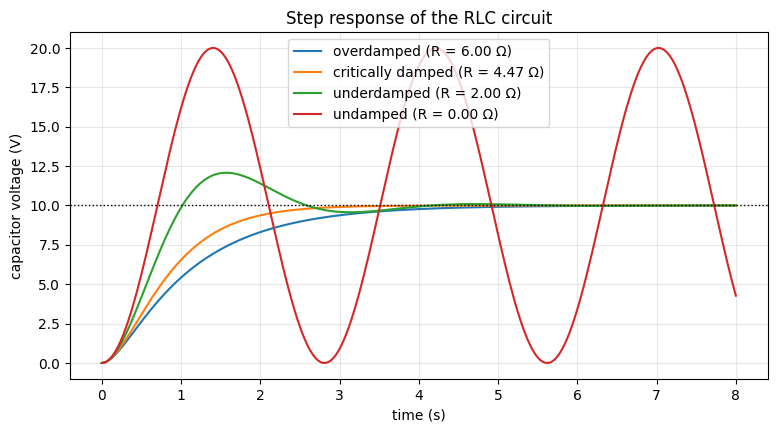

In [4]:
q = sp.Function("q")
r = sp.symbols("r")
L_N, C_N, E_STEP = 1, sp.Rational(1, 5), 10
cases = [("overdamped", sp.Integer(6)), ("critically damped", 2 * sp.sqrt(5)),
         ("underdamped", sp.Integer(2)), ("undamped", sp.Integer(0))]

t = np.linspace(0, 8, 800)
fig, ax = plt.subplots(figsize=(9, 4.5))
rlc_solutions = {}
for name, Rv in cases:
    roots = sp.solve(L_N * r**2 + Rv * r + 1 / C_N, r)
    ode = sp.Eq(L_N * q(tt).diff(tt, 2) + Rv * q(tt).diff(tt) + q(tt) / C_N, E_STEP)
    sol = sp.dsolve(ode, q(tt), ics={q(0): 0, q(tt).diff(tt).subs(tt, 0): 0})
    rlc_solutions[name] = sol.rhs
    vc = sp.lambdify(tt, sol.rhs / C_N, "numpy")          # capacitor voltage v_C = q / C
    R_float = float(Rv)
    num = solve_ivp(lambda t_, y: [y[1], (E_STEP - R_float * y[1] - y[0] / float(C_N)) / L_N],
                    (0, 8), [0, 0], t_eval=t, rtol=1e-9, atol=1e-12)
    print(f"R = {sp.nsimplify(Rv)} Ω ({name}): roots {roots}")
    show(r"\quad q(t) = ", sp.simplify(sol.rhs))
    print(f"   max |exact - numerical| = {np.max(np.abs(vc(t) - num.y[0] / float(C_N))):.2e} V")
    ax.plot(t, vc(t) * np.ones_like(t), label=f"{name} (R = {R_float:.2f} Ω)")
ax.axhline(E_STEP, color="k", ls=":", lw=1)
ax.set(xlabel="time (s)", ylabel="capacitor voltage (V)", title="Step response of the RLC circuit")
ax.legend()
plt.show()

### Sinusoidal input: undetermined coefficients and resonance
For $v_{in} = E_0\cos\omega t$, we try a **particular solution** $q_p = A\cos\omega t + B\sin\omega t$ and match coefficients. The steady-state amplitude peaks near the natural frequency $\omega_0 = 1/\sqrt{LC}$. This is **resonance**, and the peak is sharper when $R$ is smaller (higher quality factor $Q = \omega_0 L/R$).

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

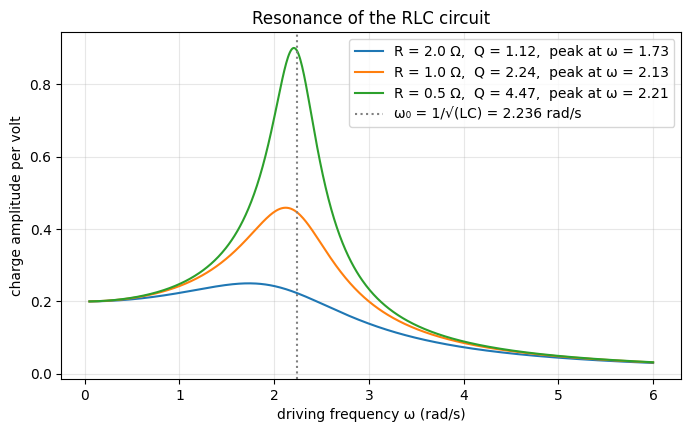

In [5]:
A_, B_ = sp.symbols("A B", real=True)                 # coefficients may be negative
W, E0, Rs = sp.symbols("omega E_0 R", positive=True)
qp = A_ * sp.cos(W * tt) + B_ * sp.sin(W * tt)
residual = sp.expand(L_N * qp.diff(tt, 2) + Rs * qp.diff(tt) + qp / C_N - E0 * sp.cos(W * tt))
coef_eqs = [residual.coeff(sp.cos(W * tt)), residual.coeff(sp.sin(W * tt))]
AB = sp.solve(coef_eqs, [A_, B_], dict=True)[0]
amplitude = sp.simplify(sp.sqrt(AB[A_] ** 2 + AB[B_] ** 2))
show(r"A = ", sp.simplify(AB[A_]))
show(r"B = ", sp.simplify(AB[B_]))
show(r"\text{Amplitude of } q_p = ", amplitude)

omega0 = 1 / np.sqrt(L_N * float(C_N))
amp_f = sp.lambdify((W, Rs, E0), amplitude, "numpy")
ws = np.linspace(0.05, 6, 600)
for Rv in [2.0, 1.0, 0.5]:
    a_ = amp_f(ws, Rv, 1.0)
    plt.plot(ws, a_, label=f"R = {Rv} Ω,  Q = {omega0 * L_N / Rv:.2f},  peak at ω = {ws[np.argmax(a_)]:.2f}")
plt.axvline(omega0, color="gray", ls=":", label=f"ω₀ = 1/√(LC) = {omega0:.3f} rad/s")
plt.xlabel("driving frequency ω (rad/s)")
plt.ylabel("charge amplitude per volt")
plt.title("Resonance of the RLC circuit")
plt.legend()
plt.show()

## 4. Switching, pulses and impulses: Laplace transforms

The **Laplace transform** $F(s) = \int_0^\infty f(t)e^{-st}\,dt$ turns derivatives into multiplication by $s$:
$$\mathcal L\{q'\} = sQ - q(0), \qquad \mathcal L\{q''\} = s^2Q - s\,q(0) - q'(0).$$
So an initial-value problem becomes an **algebra problem**, with the initial conditions built in. It also handles switches ($u(t-a)$), pulses and impulses ($\delta(t)$) neatly.

### 4.1 A table of transforms

In [6]:
for f in [sp.Integer(1), tt, sp.exp(-2 * tt), sp.sin(3 * tt), sp.cos(3 * tt),
          sp.exp(-tt) * sp.sin(2 * tt), sp.Heaviside(tt - 1), sp.DiracDelta(tt - 2)]:
    show(r"\mathcal{L}\{" + sp.latex(f) + r"\} = ", sp.laplace_transform(f, tt, s, noconds=True))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 4.2 A charged capacitor discharging through the RLC circuit
With $L = 1$, $R = 2$, $C = 0.2$, no input, $q(0) = 2$ C and $q'(0) = 0$, transforming gives
$$s^2Q - 2s + 2(sQ - 2) + 5Q = 0 .$$
We solve for $Q(s)$, split it into **partial fractions** and invert.

In [7]:
Q = sp.symbols("Q")
q0, dq0 = 2, 0
eq = sp.Eq(s**2 * Q - s * q0 - dq0 + 2 * (s * Q - q0) + 5 * Q, 0)
Q_s = sp.solve(eq, Q)[0]
show(r"Q(s) = ", Q_s)
show(r"\text{Partial fractions: } ", sp.apart(Q_s, s))
q_lap = sp.inverse_laplace_transform(Q_s, s, tt).subs(sp.Heaviside(tt), 1)
show(r"q(t) = \mathcal{L}^{-1}\{Q\} = ", sp.simplify(q_lap))

q_dsolve = sp.dsolve(sp.Eq(q(tt).diff(tt, 2) + 2 * q(tt).diff(tt) + 5 * q(tt), 0), q(tt),
                     ics={q(0): q0, q(tt).diff(tt).subs(tt, 0): dq0}).rhs
check_t = np.linspace(0.1, 6, 50)
print("Laplace solution equals dsolve solution:",
      np.allclose(sp.lambdify(tt, q_lap, "numpy")(check_t), sp.lambdify(tt, q_dsolve, "numpy")(check_t)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Laplace solution equals dsolve solution: True


### 4.3 A rectangular pulse: unit steps and the second shifting theorem
A 10 V pulse is applied from $t=1$ s to $t=3$ s: $v_{in}(t) = 10\,[u(t-1) - u(t-3)]$. The **second shifting theorem** gives $\mathcal L\{f(t-a)u(t-a)\} = e^{-as}F(s)$. So
$$V_C(s) = \underbrace{\frac{5}{s^2+2s+5}}_{H(s)}\cdot\frac{10\,(e^{-s} - e^{-3s})}{s}.$$

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Max |Laplace solution - numerical| = 1.27e-07 V


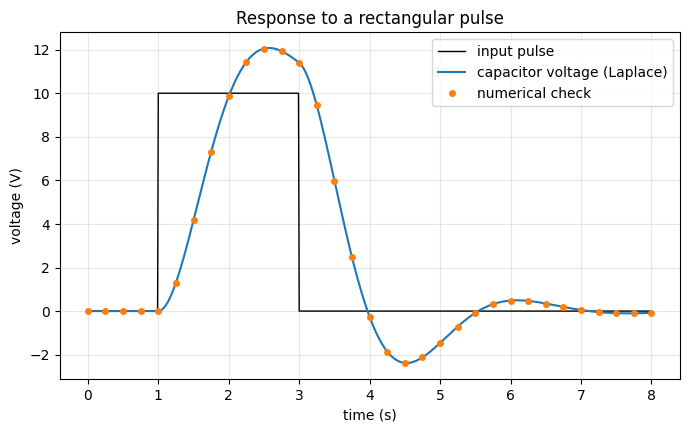

In [8]:
v_pulse = 10 * (sp.Heaviside(tt - 1) - sp.Heaviside(tt - 3))
H_s = 5 / (s**2 + 2 * s + 5)                         # transfer function V_C(s) / V_in(s)
Vin_s = sp.laplace_transform(v_pulse, tt, s, noconds=True)
show(r"V_{in}(s) = ", Vin_s)
show(r"V_C(s) = H(s)\,V_{in}(s) = ", H_s * Vin_s)

# Step response g(t) = L^-1{10 H(s)/s}, then shift it: v_C = g(t-1)u(t-1) - g(t-3)u(t-3)
G_s = sp.apart(10 * H_s / s, s)
show(r"\frac{10\,H(s)}{s} = ", G_s)
g_t = sp.inverse_laplace_transform(G_s, s, tt).subs(sp.Heaviside(tt), 1)
show(r"g(t) = ", sp.simplify(g_t))
vc_pulse = g_t.subs(tt, tt - 1) * sp.Heaviside(tt - 1) - g_t.subs(tt, tt - 3) * sp.Heaviside(tt - 3)
show(r"v_C(t) = ", vc_pulse)
vc_pulse_f = sp.lambdify(tt, vc_pulse, "numpy")

def vin_num(t_):
    return 10.0 if 1 <= t_ < 3 else 0.0

t = np.linspace(0, 8, 801)
num = solve_ivp(lambda t_, y: [y[1], vin_num(t_) - 2 * y[1] - 5 * y[0]], (0, 8), [0, 0],
                t_eval=t, max_step=0.005, rtol=1e-9, atol=1e-12)
vc_exact = vc_pulse_f(t)
print(f"Max |Laplace solution - numerical| = {np.max(np.abs(vc_exact - 5 * num.y[0])):.2e} V")

plt.plot(t, [vin_num(x) for x in t], "k", lw=1, label="input pulse")
plt.plot(t, vc_exact, label="capacitor voltage (Laplace)")
plt.plot(t[::25], 5 * num.y[0][::25], "o", ms=4, label="numerical check")
plt.xlabel("time (s)")
plt.ylabel("voltage (V)")
plt.title("Response to a rectangular pulse")
plt.legend()
plt.show()

### 4.4 Impulse response, poles and convolution
* The **impulse response** $h(t) = \mathcal L^{-1}\{H(s)\}$ is the output when the input is a Dirac delta, i.e. a very short, sharp kick.
* The **poles** of $H(s)$ (the roots of the denominator) are exactly the roots of the characteristic equation. Poles in the left half-plane mean the circuit is **stable**.
* The **convolution theorem**, $\mathcal L\{h * v\} = H(s)V(s)$, means the response to *any* input is $v_C(t) = \int_0^t h(\tau)\,v_{in}(t-\tau)\,d\tau$.

<IPython.core.display.Math object>

Poles of H(s): [-1 - 2*I, -1 + 2*I]  -> real parts negative: stable, imaginary parts ±2: rings at 2 rad/s
Max |convolution - Laplace solution| = 0.074 V (discretisation error, shrinks with dt)


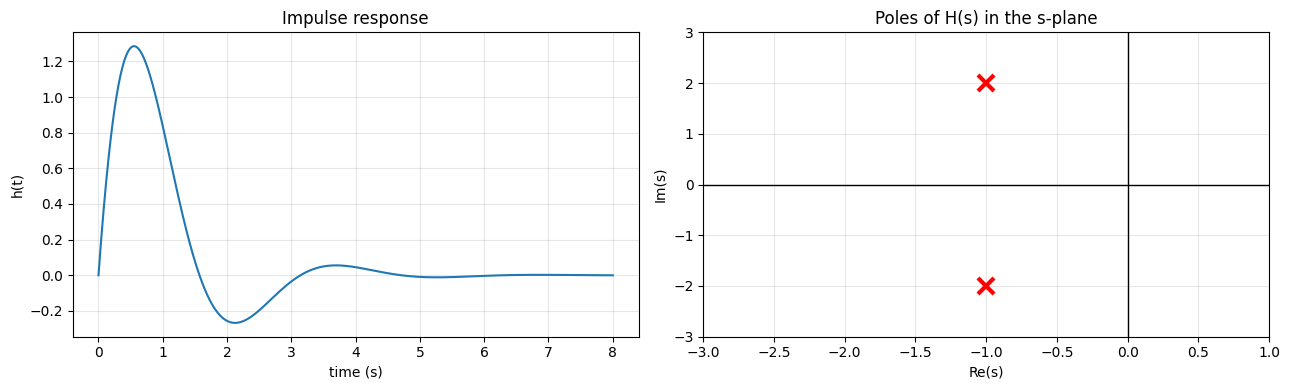

In [9]:
h_t = sp.inverse_laplace_transform(H_s, s, tt).subs(sp.Heaviside(tt), 1)
show(r"h(t) = \mathcal{L}^{-1}\{H(s)\} = ", sp.simplify(h_t))
z = sp.symbols("z")                              # unrestricted symbol, so complex roots are kept
poles = sp.solve(sp.denom(H_s).subs(s, z), z)
print("Poles of H(s):", poles, " -> real parts negative: stable, imaginary parts ±2: rings at 2 rad/s")

dt = t[1] - t[0]
h_num = sp.lambdify(tt, h_t, "numpy")(t)
vin_arr = np.array([vin_num(x) for x in t])
conv = np.convolve(h_num, vin_arr)[: len(t)] * dt
print(f"Max |convolution - Laplace solution| = {np.max(np.abs(conv - vc_exact)):.3f} V (discretisation error, shrinks with dt)")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(t, h_num)
axs[0].set(xlabel="time (s)", ylabel="h(t)", title="Impulse response")
pole_vals = [complex(p) for p in poles]
axs[1].plot([p.real for p in pole_vals], [p.imag for p in pole_vals], "rx", ms=12, mew=3)
axs[1].axvline(0, color="k", lw=1)
axs[1].axhline(0, color="k", lw=1)
axs[1].set(xlim=(-3, 1), ylim=(-3, 3), xlabel="Re(s)", ylabel="Im(s)", title="Poles of H(s) in the s-plane")
plt.tight_layout()
plt.show()

## 5. Multi-stage filters: systems of differential equations

### 5.1 The RLC circuit as a first-order system
With state $\mathbf x = [q,\ i]^{\mathsf T}$, the second-order equation becomes the system
$$\mathbf x' = A\mathbf x, \qquad A = \begin{pmatrix} 0 & 1 \\ -\frac{1}{LC} & -\frac{R}{L}\end{pmatrix}.$$
The **eigenvalues** of $A$ are the characteristic roots. A **phase portrait** shows every possible trajectory: a **spiral** for an underdamped circuit and a **node** for an overdamped one.

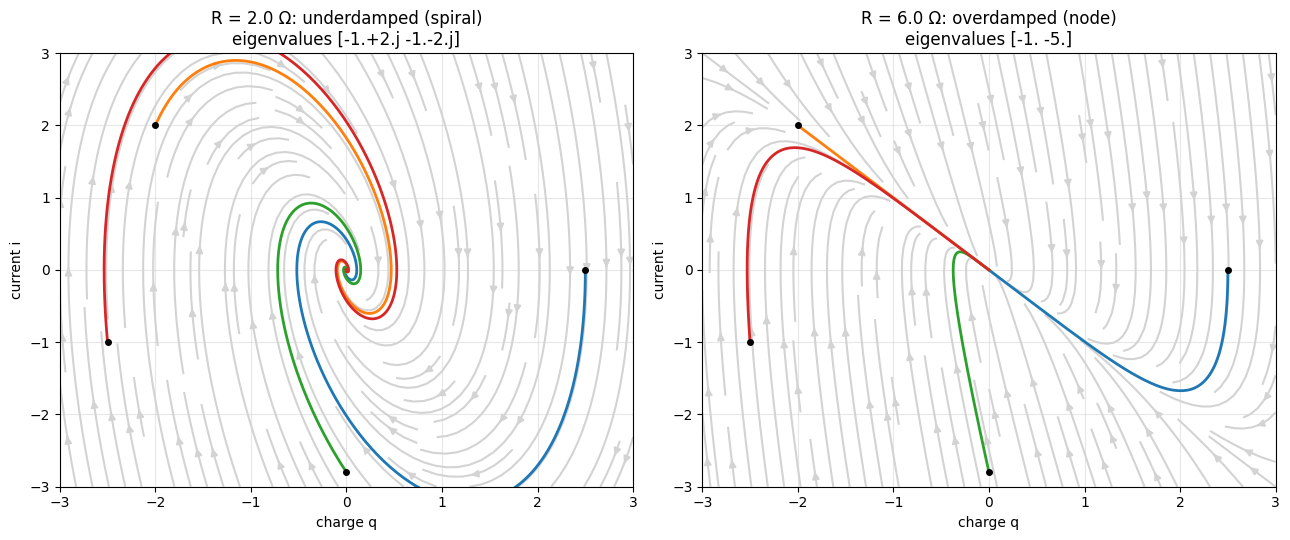

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
grid = np.linspace(-3, 3, 25)
Qg, Ig = np.meshgrid(grid, grid)
for ax, Rv, name in [(axs[0], 2.0, "underdamped (spiral)"), (axs[1], 6.0, "overdamped (node)")]:
    A = np.array([[0, 1], [-5.0, -Rv]])
    lam = np.linalg.eigvals(A)
    ax.streamplot(Qg, Ig, A[0, 0] * Qg + A[0, 1] * Ig, A[1, 0] * Qg + A[1, 1] * Ig, color="lightgray", density=1.2)
    for start in [(2.5, 0), (-2, 2), (0, -2.8), (-2.5, -1)]:
        traj = solve_ivp(lambda t_, x: A @ x, (0, 10), start, t_eval=np.linspace(0, 10, 800))
        ax.plot(traj.y[0], traj.y[1], lw=2)
        ax.plot(*start, "ko", ms=4)
    ax.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="charge q", ylabel="current i",
           title=f"R = {Rv} Ω: {name}\neigenvalues {np.round(lam, 3)}")
plt.tight_layout()
plt.show()

### 5.2 A two-stage RC filter
Two RC sections in cascade (each with $R = 1$ kΩ and $C = 1$ µF) give a **coupled system** for the two capacitor voltages:
$$\begin{pmatrix} v_1 \\ v_2 \end{pmatrix}' = \frac{1}{RC}\begin{pmatrix} -2 & 1 \\ 1 & -1 \end{pmatrix}\begin{pmatrix} v_1 \\ v_2 \end{pmatrix} + \frac{1}{RC}\begin{pmatrix} 1 \\ 0 \end{pmatrix} v_{in}.$$
For a step input, the solution is $\mathbf x(t) = \mathbf x_{ss} + \sum_k c_k e^{\lambda_k t}\mathbf u_k$, built from the **eigenvalues and eigenvectors** of the matrix.

Eigenvalues: [-2618.03398875  -381.96601125] 1/s  ->  time constants [0.382 2.618] ms
Steady state: [5. 5.] V
Max |eigenvector solution - numerical| = 1.01e-09 V
High-frequency roll-off: one stage -20.0 dB/decade, two stages -40.0 dB/decade


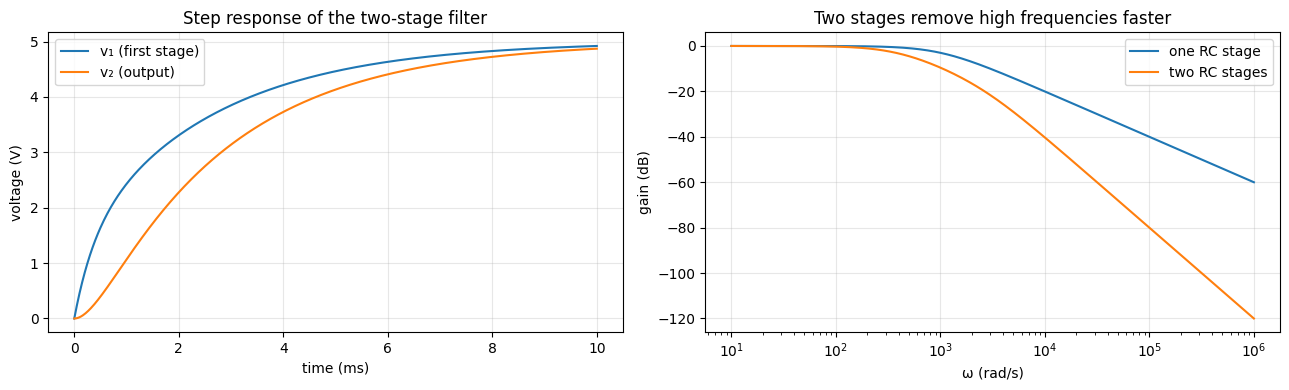

In [11]:
R2, C2 = 1e3, 1e-6
k = 1 / (R2 * C2)
A2 = k * np.array([[-2.0, 1.0], [1.0, -1.0]])
B2 = k * np.array([1.0, 0.0])
lam, U = np.linalg.eig(A2)
x_ss = -np.linalg.solve(A2, B2 * V0)                    # steady state: A x + B v_in = 0
coef = np.linalg.solve(U, np.zeros(2) - x_ss)           # match the initial condition x(0) = 0
t = np.linspace(0, 10e-3, 600)
x_t = x_ss[:, None] + U @ (coef[:, None] * np.exp(np.outer(lam, t)))
num = solve_ivp(lambda t_, x: A2 @ x + B2 * V0, (0, t[-1]), [0, 0], t_eval=t, rtol=1e-9, atol=1e-12)
print(f"Eigenvalues: {lam} 1/s  ->  time constants {np.round(-1e3 / lam, 3)} ms")
print(f"Steady state: {x_ss} V")
print(f"Max |eigenvector solution - numerical| = {np.max(np.abs(x_t - num.y)):.2e} V")

# Frequency response: H(jω) = [0 1] (jωI - A)^(-1) B
ws = np.logspace(1, 6, 400)
H2 = np.array([np.linalg.solve(1j * wv * np.eye(2) - A2, B2)[1] for wv in ws])
H1 = 1 / (1 + 1j * ws * R2 * C2)
hi = ws > 1e5
slope1 = np.polyfit(np.log10(ws[hi]), 20 * np.log10(np.abs(H1[hi])), 1)[0]
slope2 = np.polyfit(np.log10(ws[hi]), 20 * np.log10(np.abs(H2[hi])), 1)[0]
print(f"High-frequency roll-off: one stage {slope1:.1f} dB/decade, two stages {slope2:.1f} dB/decade")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(1e3 * t, x_t[0], label="v₁ (first stage)")
axs[0].plot(1e3 * t, x_t[1], label="v₂ (output)")
axs[0].set(xlabel="time (ms)", ylabel="voltage (V)", title="Step response of the two-stage filter")
axs[0].legend()
axs[1].semilogx(ws, 20 * np.log10(np.abs(H1)), label="one RC stage")
axs[1].semilogx(ws, 20 * np.log10(np.abs(H2)), label="two RC stages")
axs[1].set(xlabel="ω (rad/s)", ylabel="gain (dB)", title="Two stages remove high frequencies faster")
axs[1].legend()
plt.tight_layout()
plt.show()

## 6. A time-varying capacitor: series solutions

A capacitive sensor, such as a MEMS plate moving away at a steady speed, has a capacitance that falls over time: $1/C(t) = \kappa t$. In an LC circuit this gives
$$L\,q'' + \kappa t\, q = 0 .$$
Rescaling time (with $\tau = (\kappa/L)^{1/3}t$) gives the **Airy-type equation**
$$y'' + t\,y = 0, \qquad y(0) = 1,\ y'(0) = 0 .$$
Its coefficients are not constant, so the characteristic-equation method fails. Since $t=0$ is an **ordinary point**, we look for a **power series** $y = \sum a_n t^n$. Substituting and matching powers of $t$ gives
$$2a_2 = 0, \qquad (n+2)(n+1)\,a_{n+2} + a_{n-1} = 0 \;\Rightarrow\; a_{n+2} = -\frac{a_{n-1}}{(n+2)(n+1)} \quad (n \ge 1).$$

First coefficients a0..a12: [ 1.00000e+00  0.00000e+00  0.00000e+00 -1.66667e-01 -0.00000e+00
 -0.00000e+00  5.55600e-03  0.00000e+00  0.00000e+00 -7.70000e-05
 -0.00000e+00 -0.00000e+00  1.00000e-06]
Only every third coefficient is non-zero: y = 1 - t³/6 + t⁶/180 - ...

Max |Airy solution - numerical| = 8.94e-11


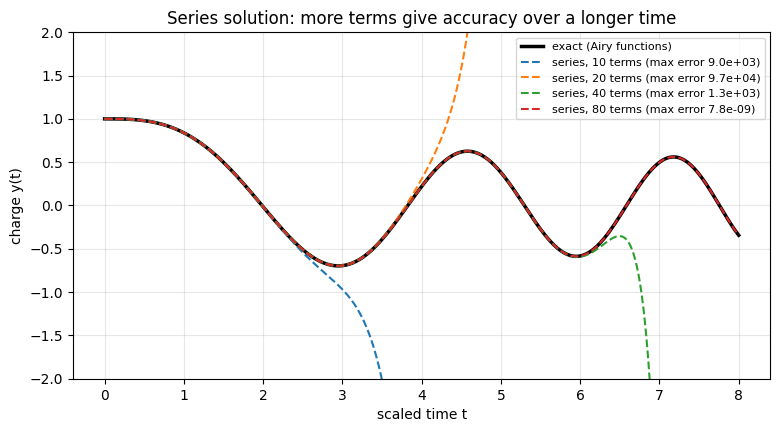

The oscillation speeds up as 1/C grows, which the constant-coefficient methods of Section 3 cannot describe.


In [12]:
def series_coeffs(n_terms, a0=1.0, a1=0.0):
    a = np.zeros(n_terms)
    a[0], a[1] = a0, a1                         # a2 = 0 from the t^0 equation
    for n in range(1, n_terms - 2):
        a[n + 2] = -a[n - 1] / ((n + 2) * (n + 1))
    return a

def series_sum(t_arr, a):
    return sum(c * t_arr ** n for n, c in enumerate(a))

a = series_coeffs(15)
print("First coefficients a0..a12:", np.round(a[:13], 6))
print("Only every third coefficient is non-zero: y = 1 - t³/6 + t⁶/180 - ...")

# Exact solution in terms of Airy functions: y = c1·Ai(-t) + c2·Bi(-t)
Ai0, Aip0, Bi0, Bip0 = airy(0.0)
c1, c2 = np.linalg.solve(np.array([[Ai0, Bi0], [-Aip0, -Bip0]]), np.array([1.0, 0.0]))
t = np.linspace(0, 8, 400)
Ai, _, Bi, _ = airy(-t)
y_exact = c1 * Ai + c2 * Bi
num = solve_ivp(lambda t_, y: [y[1], -t_ * y[0]], (0, 8), [1.0, 0.0], t_eval=t, rtol=1e-10, atol=1e-12)
print(f"\nMax |Airy solution - numerical| = {np.max(np.abs(y_exact - num.y[0])):.2e}")

plt.figure(figsize=(9, 4.5))
plt.plot(t, y_exact, "k", lw=2.5, label="exact (Airy functions)")
for n_terms in [10, 20, 40, 80]:
    ys = series_sum(t, series_coeffs(n_terms))
    plt.plot(t, ys, "--", label=f"series, {n_terms} terms (max error {np.max(np.abs(ys - y_exact)):.1e})")
plt.ylim(-2, 2)
plt.xlabel("scaled time t")
plt.ylabel("charge y(t)")
plt.title("Series solution: more terms give accuracy over a longer time")
plt.legend(fontsize=8)
plt.show()
print("The oscillation speeds up as 1/C grows, which the constant-coefficient methods of Section 3 cannot describe.")

## 7. Square-wave interference: Fourier series

A nearby digital clock produces a ±5 V square wave at $f_0 = 1$ kHz. Any periodic signal can be written as a **Fourier series**:
$$f(t) = \frac{a_0}{2} + \sum_{n=1}^{\infty}\big(a_n\cos n\omega_0 t + b_n\sin n\omega_0 t\big), \qquad b_n = \frac{2}{T}\int_0^T f(t)\sin(n\omega_0 t)\,dt .$$
For the square wave, $a_n = 0$ and $b_n = \dfrac{4A}{n\pi}$ for odd $n$ (zero for even $n$). So the clock contains energy at 1, 3, 5, 7, … kHz.

 n    b_n numerical   b_n formula 4A/(nπ)   a_n numerical
 1         6.36620               6.36620        -5.0e-04
 2        -0.00000               0.00000         5.0e-04
 3         2.12207               2.12207        -5.0e-04
 4        -0.00000               0.00000         5.0e-04
 5         1.27324               1.27324        -5.0e-04
 6         0.00000               0.00000         5.0e-04
 7         0.90946               0.90946        -5.0e-04


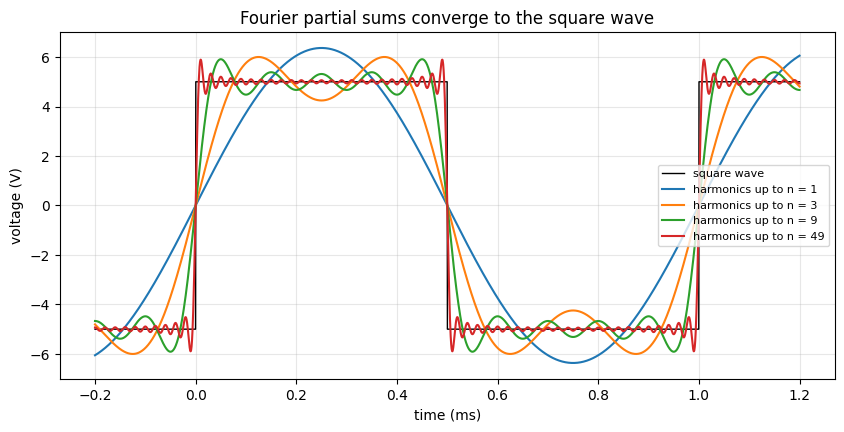

Gibbs phenomenon: with 100 harmonics the overshoot is still 8.95% of the jump (theory ≈ 8.95%)
Parseval: mean square = 24.9988 V²,  Σ b_n²/2 = 24.9995 V²
Fraction of power in the fundamental = 8/π² = 0.8106


In [13]:
F0, AMP = 1000.0, 5.0
W0, T0 = 2 * np.pi * F0, 1 / F0

def square(t_):
    return AMP * np.sign(np.sin(W0 * t_))

tp = np.linspace(0, T0, 20000, endpoint=False)
print(" n    b_n numerical   b_n formula 4A/(nπ)   a_n numerical")
for n in range(1, 8):
    bn = 2 * np.mean(square(tp) * np.sin(n * W0 * tp))
    an = 2 * np.mean(square(tp) * np.cos(n * W0 * tp))
    formula = 4 * AMP / (n * np.pi) if n % 2 else 0.0
    print(f"{n:2d}   {bn:13.5f}   {formula:19.5f}   {an:13.1e}")

def partial_sum(t_, N):
    return sum(4 * AMP / (n * np.pi) * np.sin(n * W0 * t_) for n in range(1, N + 1, 2))

t = np.linspace(-0.2 * T0, 1.2 * T0, 3000)
plt.figure(figsize=(10, 4.5))
plt.plot(1e3 * t, square(t), "k", lw=1, label="square wave")
for N in [1, 3, 9, 49]:
    plt.plot(1e3 * t, partial_sum(t, N), label=f"harmonics up to n = {N}")
plt.xlabel("time (ms)")
plt.ylabel("voltage (V)")
plt.title("Fourier partial sums converge to the square wave")
plt.legend(fontsize=8)
plt.show()

t_fine = np.linspace(0, 0.05 * T0, 20000)
overshoot = (partial_sum(t_fine, 199).max() - AMP) / (2 * AMP)
print(f"Gibbs phenomenon: with 100 harmonics the overshoot is still {100*overshoot:.2f}% of the jump (theory ≈ 8.95%)")

power_time = np.mean(square(tp) ** 2)
power_series = sum((4 * AMP / (n * np.pi)) ** 2 / 2 for n in range(1, 20001, 2))
print(f"Parseval: mean square = {power_time:.4f} V²,  Σ b_n²/2 = {power_series:.4f} V²")
print(f"Fraction of power in the fundamental = 8/π² = {8/np.pi**2:.4f}")

### A tuned RLC band-pass filter picks out one harmonic
A series RLC circuit with its output taken across $R$ passes frequencies near $\omega_0 = 1/\sqrt{LC}$ and blocks the rest:
$$H(j\omega) = \frac{R}{R + j\left(\omega L - \frac{1}{\omega C}\right)}.$$
We tune it to **3 kHz**. Because the circuit is linear, each harmonic passes through separately (**superposition**):
$$v_{out}(t) = \sum_n b_n\,|H(jn\omega_0)|\,\sin\!\big(n\omega_0 t + \angle H(jn\omega_0)\big).$$
We check this against a direct numerical solution of the circuit's ODE.

L = 10 mH, C = 281.4 nF, R = 20 Ω  ->  tuned to 3000 Hz, Q = 9.4

 n   input b_n (V)   |H|      output amplitude (V)
 1         6.3662   0.0398         0.2531
 3         2.1221   1.0000         2.1221
 5         1.2732   0.0990         0.1260
 7         0.9095   0.0556         0.0506
 9         0.7074   0.0398         0.0281

Steady state after 39 periods: max |Fourier - ODE| = 0.003 V (output peak ≈ 2.48 V)


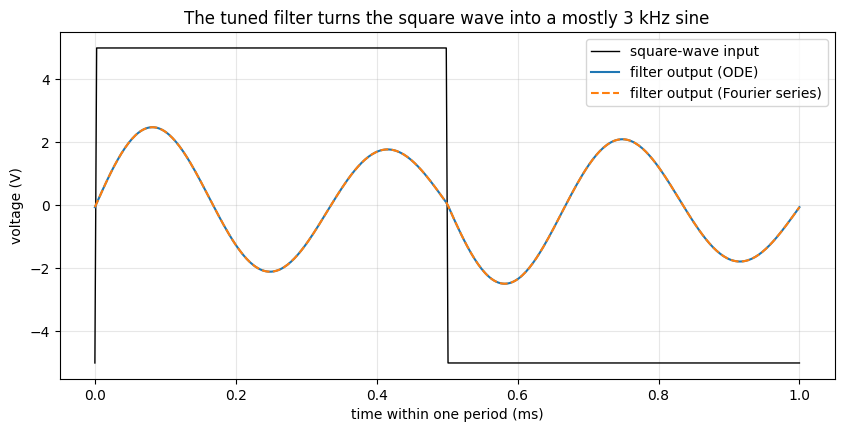

In [14]:
L_BP, R_BP = 10e-3, 20.0
F_TUNE = 3 * F0
C_BP = 1 / ((2 * np.pi * F_TUNE) ** 2 * L_BP)
Q_BP = 2 * np.pi * F_TUNE * L_BP / R_BP
print(f"L = {L_BP*1e3:.0f} mH, C = {C_BP*1e9:.1f} nF, R = {R_BP:.0f} Ω  ->  tuned to {F_TUNE:.0f} Hz, Q = {Q_BP:.1f}")

def H_bp(wv):
    return R_BP / (R_BP + 1j * (wv * L_BP - 1 / (wv * C_BP)))

print("\n n   input b_n (V)   |H|      output amplitude (V)")
for n in range(1, 10, 2):
    bn = 4 * AMP / (n * np.pi)
    print(f"{n:2d}   {bn:12.4f}   {abs(H_bp(n * W0)):.4f}   {bn * abs(H_bp(n * W0)):12.4f}")

t_last = np.linspace(39 * T0, 40 * T0, 400)
v_fourier = sum(4 * AMP / (n * np.pi) * abs(H_bp(n * W0)) * np.sin(n * W0 * t_last + np.angle(H_bp(n * W0)))
                for n in range(1, 400, 2))

def rlc_bp(t_, x):
    qv, iv = x
    return [iv, (square(t_) - R_BP * iv - qv / C_BP) / L_BP]

sim = solve_ivp(rlc_bp, (0, 40 * T0), [0, 0], t_eval=t_last, max_step=T0 / 400, rtol=1e-8, atol=1e-12)
v_ode = R_BP * sim.y[1]
print(f"\nSteady state after 39 periods: max |Fourier - ODE| = {np.max(np.abs(v_fourier - v_ode)):.3f} V "
      f"(output peak ≈ {np.max(np.abs(v_ode)):.2f} V)")

plt.figure(figsize=(10, 4.5))
plt.plot(1e3 * (t_last - 39 * T0), square(t_last), "k", lw=1, label="square-wave input")
plt.plot(1e3 * (t_last - 39 * T0), v_ode, label="filter output (ODE)")
plt.plot(1e3 * (t_last - 39 * T0), v_fourier, "--", label="filter output (Fourier series)")
plt.xlabel("time within one period (ms)")
plt.ylabel("voltage (V)")
plt.title("The tuned filter turns the square wave into a mostly 3 kHz sine")
plt.legend()
plt.show()

## 8. Noise removal: the Fourier transform

The **Fourier transform** $X(f) = \int_{-\infty}^{\infty} x(t)e^{-j2\pi ft}\,dt$ extends Fourier series to signals that are *not* periodic. It shows how much of a signal lies at each frequency. In practice we compute it with the **FFT**.

### 8.1 A pulse and its spectrum
A rectangular pulse of height $A$ and width $\tau$ has transform $X(f) = A\tau\,\operatorname{sinc}(f\tau)$. Shorter pulses spread over **wider** frequency ranges.

τ = 20 ms: max |FFT - exact| = 3.01e-08
τ = 5 ms: max |FFT - exact| = 2.64e-08


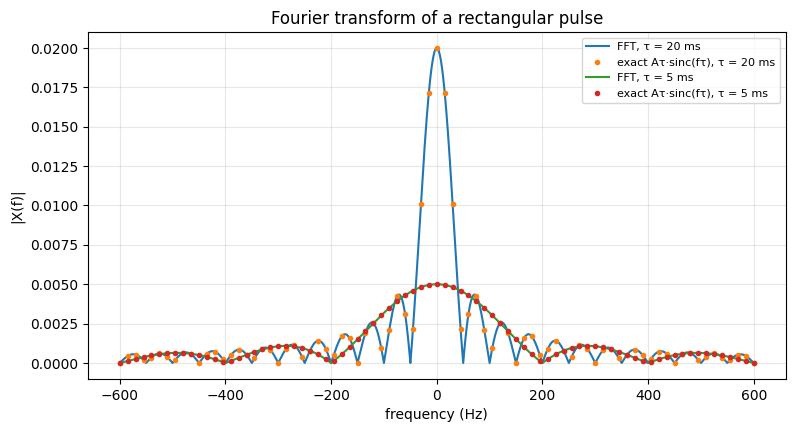

In [15]:
fs_p, A_p = 1e5, 1.0
t = np.arange(-0.5, 0.5, 1 / fs_p)
fig, ax = plt.subplots(figsize=(9, 4.5))
for tau_p in [0.02, 0.005]:
    x = np.where(np.abs(t) <= tau_p / 2, A_p, 0.0)
    X = np.fft.fftshift(np.fft.fft(x)) / fs_p
    f = np.fft.fftshift(np.fft.fftfreq(len(t), 1 / fs_p))
    exact = A_p * tau_p * np.abs(np.sinc(f * tau_p))
    keep = np.abs(f) <= 600
    ax.plot(f[keep], np.abs(X[keep]), label=f"FFT, τ = {tau_p*1e3:.0f} ms")
    ax.plot(f[keep][::15], exact[keep][::15], "o", ms=3, label=f"exact Aτ·sinc(fτ), τ = {tau_p*1e3:.0f} ms")
    print(f"τ = {tau_p*1e3:.0f} ms: max |FFT - exact| = {np.max(np.abs(np.abs(X[keep]) - exact[keep])):.2e}")
ax.set(xlabel="frequency (Hz)", ylabel="|X(f)|", title="Fourier transform of a rectangular pulse")
ax.legend(fontsize=8)
plt.show()

### 8.2 Cleaning a noisy sensor signal
The sensor signal contains 5 Hz and 12 Hz components. It is buried in **50 Hz mains hum** and random noise. The spectrum shows where each part lives. We then design a **second-order RLC low-pass filter** (Butterworth, $\zeta = 0.707$, cut-off 20 Hz):
$$H(s) = \frac{\omega_c^2}{s^2 + 2\zeta\omega_c s + \omega_c^2}, \qquad \omega_c = \frac{1}{\sqrt{LC}},\quad \zeta = \frac{R}{2}\sqrt{\frac{C}{L}} .$$
We apply the filter in two ways:
* in the **time domain**, by solving its ODE
* in the **frequency domain**, by multiplying the spectrum by $H(j2\pi f)$

In [16]:
FS, DUR = 2000.0, 2.0
t = np.arange(0, DUR, 1 / FS)
clean = 1.0 * np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 12 * t)
hum = 0.8 * np.sin(2 * np.pi * 50 * t)
noise = rng.normal(0, 0.5, t.size)
noisy = clean + hum + noise

FC, ZETA = 20.0, 1 / np.sqrt(2)
WC = 2 * np.pi * FC
L_LP = 1.0
C_LP = 1 / (WC ** 2 * L_LP)
R_LP = 2 * ZETA * np.sqrt(L_LP / C_LP)
print(f"Filter components: L = {L_LP} H, C = {C_LP*1e6:.1f} µF, R = {R_LP:.1f} Ω")
num_lp, den_lp = [WC ** 2], [1, 2 * ZETA * WC, WC ** 2]

def H_lp(f_):
    s_ = 1j * 2 * np.pi * f_
    return WC ** 2 / (s_ ** 2 + 2 * ZETA * WC * s_ + WC ** 2)

print(f"Gain at 5 Hz: {abs(H_lp(5)):.3f};  at 50 Hz: {20*np.log10(abs(H_lp(50))):.1f} dB;  at 500 Hz: {20*np.log10(abs(H_lp(500))):.1f} dB")

# Time domain: solve the filter's ODE for the sampled input
_, out_time, _ = lsim((num_lp, den_lp), noisy, t)
_, ref_time, _ = lsim((num_lp, den_lp), clean, t)

# Frequency domain: multiply the spectrum by H
f = np.fft.rfftfreq(t.size, 1 / FS)
spec_noisy = np.fft.rfft(noisy)
out_freq = np.fft.irfft(spec_noisy * H_lp(f), n=t.size)
ref_freq = np.fft.irfft(np.fft.rfft(clean) * H_lp(f), n=t.size)

def snr_db(signal, error):
    return 10 * np.log10(np.mean(signal ** 2) / np.mean(error ** 2))

settled = t > 0.25          # ignore the start-up transient of the time-domain filter
print(f"\nSignal-to-noise ratio before filtering:         {snr_db(clean, noisy - clean):6.2f} dB")
print(f"After the filter (time domain, ODE):            {snr_db(ref_time[settled], out_time[settled] - ref_time[settled]):6.2f} dB")
print(f"After the filter (frequency domain, FFT · H):   {snr_db(ref_freq, out_freq - ref_freq):6.2f} dB")

Filter components: L = 1.0 H, C = 63.3 µF, R = 177.7 Ω
Gain at 5 Hz: 0.998;  at 50 Hz: -16.0 dB;  at 500 Hz: -55.9 dB

Signal-to-noise ratio before filtering:           0.48 dB
After the filter (time domain, ODE):             16.51 dB
After the filter (frequency domain, FFT · H):    16.39 dB


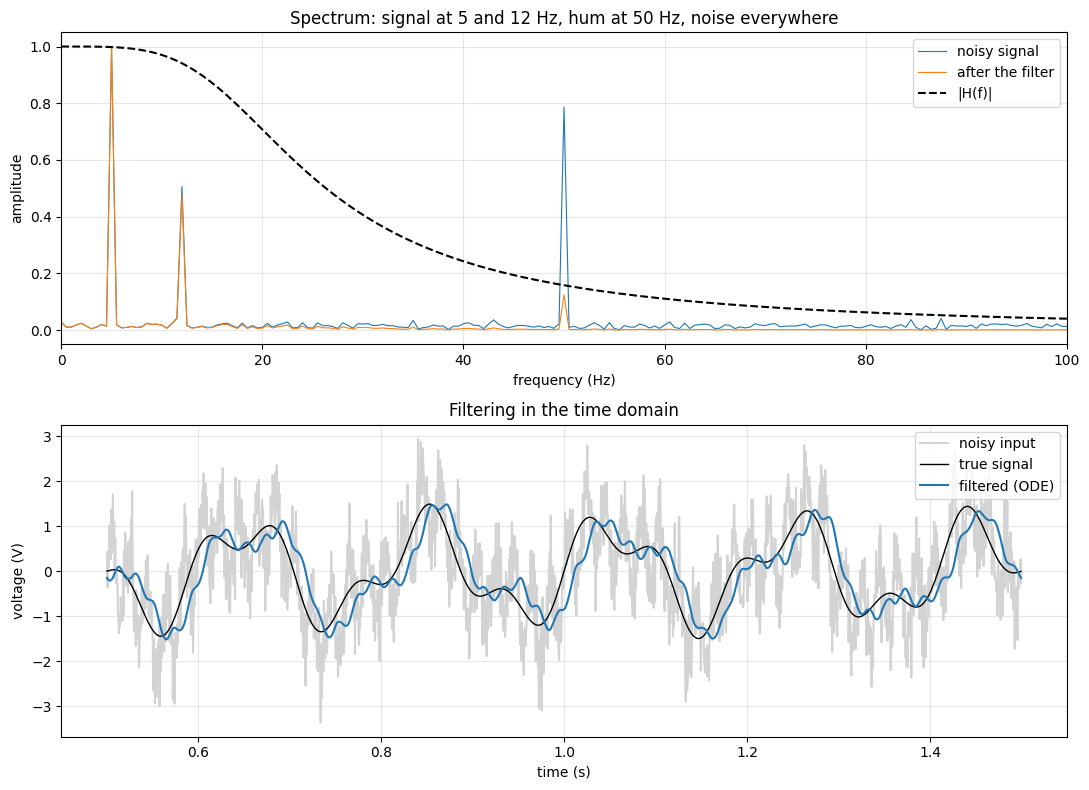

In [17]:
fig, axs = plt.subplots(2, 1, figsize=(11, 8))
amp_spec = 2 * np.abs(spec_noisy) / t.size
axs[0].plot(f, amp_spec, lw=0.8, label="noisy signal")
axs[0].plot(f, amp_spec * np.abs(H_lp(f)), lw=0.8, label="after the filter")
axs[0].plot(f, np.abs(H_lp(f)), "k--", label="|H(f)|")
axs[0].set(xlim=(0, 100), xlabel="frequency (Hz)", ylabel="amplitude", title="Spectrum: signal at 5 and 12 Hz, hum at 50 Hz, noise everywhere")
axs[0].legend()
window = (t > 0.5) & (t < 1.5)
axs[1].plot(t[window], noisy[window], color="lightgray", label="noisy input")
axs[1].plot(t[window], clean[window], "k", lw=1, label="true signal")
axs[1].plot(t[window], out_time[window], label="filtered (ODE)")
axs[1].set(xlabel="time (s)", ylabel="voltage (V)", title="Filtering in the time domain")
axs[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

### 8.3 Laplace and Fourier are linked
For a stable circuit, putting $s = j\omega$ in the transfer function gives the Fourier transform of the impulse response: $H(j\omega) = \mathcal F\{h(t)\}$. We check this numerically with the RLC circuit from Section 4, where $h(t) = \tfrac52 e^{-t}\sin 2t$.

Max |FFT of h(t) - H(jω)| for ω ≤ 10 rad/s: 4.17e-07


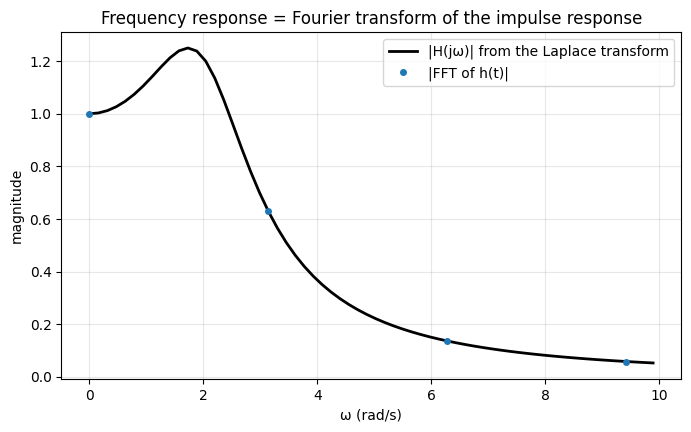

In [18]:
dt_h = 1e-3
t_h = np.arange(0, 40, dt_h)
h_vals = 2.5 * np.exp(-t_h) * np.sin(2 * t_h)
H_fft = np.fft.rfft(h_vals) * dt_h
omega = 2 * np.pi * np.fft.rfftfreq(t_h.size, dt_h)
H_exact = 5 / (5 - omega ** 2 + 2j * omega)
band = omega <= 10
print(f"Max |FFT of h(t) - H(jω)| for ω ≤ 10 rad/s: {np.max(np.abs(H_fft[band] - H_exact[band])):.2e}")

plt.plot(omega[band], np.abs(H_exact[band]), "k", lw=2, label="|H(jω)| from the Laplace transform")
plt.plot(omega[band][::20], np.abs(H_fft[band][::20]), "o", ms=4, label="|FFT of h(t)|")
plt.xlabel("ω (rad/s)")
plt.ylabel("magnitude")
plt.title("Frequency response = Fourier transform of the impulse response")
plt.legend()
plt.show()

## 9. The cable: boundary-value problems and partial differential equations

### 9.1 A leaky cable at DC: a boundary-value problem
A long cable has series resistance $r$ (Ω/m) and leakage conductance $g$ (S/m) through its insulation. In steady state, the voltage along it satisfies
$$\frac{d^2V}{dx^2} = rg\,V, \qquad V(0) = V_{in}, \quad \frac{dV}{dx}(L) = 0 \ \ (\text{far end open}).$$
The conditions are given at **two different points**, so this is a **boundary-value problem**, not an initial-value problem. With $\alpha = \sqrt{rg}$, the exact solution is
$$V(x) = V_{in}\,\frac{\cosh\big(\alpha(L - x)\big)}{\cosh(\alpha L)} .$$
We also solve it with **finite differences**, which turn it into a linear system, and with SciPy's `solve_bvp`.

α = 1.0e-04 1/m,  αL = 2.00
Voltage at the far end: exact 26.580 V, finite differences 26.580 V, solve_bvp 26.580 V (status: The algorithm converged to the desired accuracy.)
Current drawn from the source = (V_in α / r)·tanh(αL) = 0.9640 A


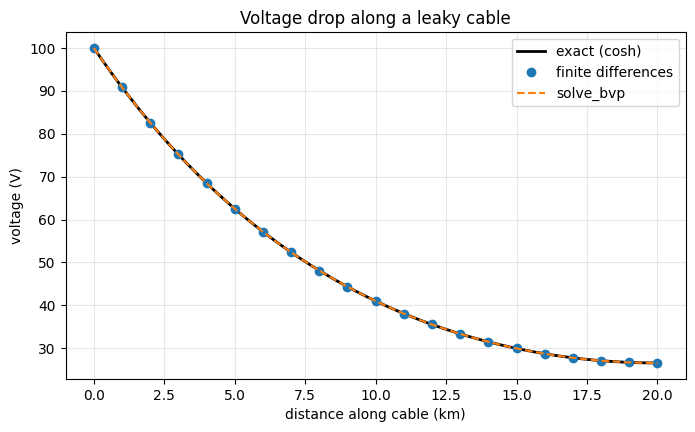

In [19]:
V_IN, r_c, g_c, L_CAB = 100.0, 0.01, 1e-6, 20e3
alpha = np.sqrt(r_c * g_c)
x = np.linspace(0, L_CAB, 201)
V_exact = V_IN * np.cosh(alpha * (L_CAB - x)) / np.cosh(alpha * L_CAB)

# Finite differences: (V[i-1] - 2V[i] + V[i+1]) / h² = α² V[i]
N, h = len(x) - 1, x[1] - x[0]
M = np.zeros((N + 1, N + 1))
rhs = np.zeros(N + 1)
M[0, 0], rhs[0] = 1.0, V_IN                                      # V(0) = V_in
for i in range(1, N):
    M[i, i - 1], M[i, i], M[i, i + 1] = 1.0, -2.0 - (alpha * h) ** 2, 1.0
M[N, N - 1], M[N, N] = 2.0, -2.0 - (alpha * h) ** 2             # V'(L) = 0 via a ghost node
V_fd = np.linalg.solve(M, rhs)

bvp = solve_bvp(lambda x_, y: np.vstack([y[1], alpha ** 2 * y[0]]),
                lambda ya, yb: np.array([ya[0] - V_IN, yb[1]]),
                x, np.vstack([np.full_like(x, V_IN), np.zeros_like(x)]))

print(f"α = {alpha:.1e} 1/m,  αL = {alpha*L_CAB:.2f}")
print(f"Voltage at the far end: exact {V_exact[-1]:.3f} V, finite differences {V_fd[-1]:.3f} V, "
      f"solve_bvp {bvp.sol(L_CAB)[0]:.3f} V (status: {bvp.message})")
print(f"Current drawn from the source = (V_in α / r)·tanh(αL) = {V_IN*alpha/r_c*np.tanh(alpha*L_CAB):.4f} A")

plt.plot(x / 1e3, V_exact, "k", lw=2, label="exact (cosh)")
plt.plot(x[::10] / 1e3, V_fd[::10], "o", label="finite differences")
plt.plot(x / 1e3, bvp.sol(x)[0], "--", label="solve_bvp")
plt.xlabel("distance along cable (km)")
plt.ylabel("voltage (V)")
plt.title("Voltage drop along a leaky cable")
plt.legend()
plt.show()

### 9.2 A long resistive wire: the diffusion equation (PDE)
Inside a chip, or along a long undersea cable, the wire's resistance $r$ and capacitance $c$ per unit length dominate. The voltage $v(x,t)$ then obeys the **diffusion (heat) equation**:
$$\frac{\partial v}{\partial t} = \frac{1}{rc}\,\frac{\partial^2 v}{\partial x^2}.$$
In scaled units ($x \in [0,1]$, $rc\,L^2 = 1$), a step of 1 V is applied at the near end, and the far end is open:
$$v(0,t) = 1, \quad \frac{\partial v}{\partial x}(1,t) = 0, \quad v(x,0) = 0 .$$
**Separation of variables** and a **Fourier series** in the modes $\sin(\lambda_n x)$, with $\lambda_n = \frac{(2n-1)\pi}{2}$, give
$$v(x,t) = 1 - \sum_{n=1}^{\infty}\frac{4}{(2n-1)\pi}\,\sin(\lambda_n x)\,e^{-\lambda_n^2 t}.$$

t = 0.02: max |series - finite differences| = 1.02e-03
t = 0.1: max |series - finite differences| = 2.01e-04
t = 0.3: max |series - finite differences| = 9.76e-05
t = 0.6: max |series - finite differences| = 7.32e-05


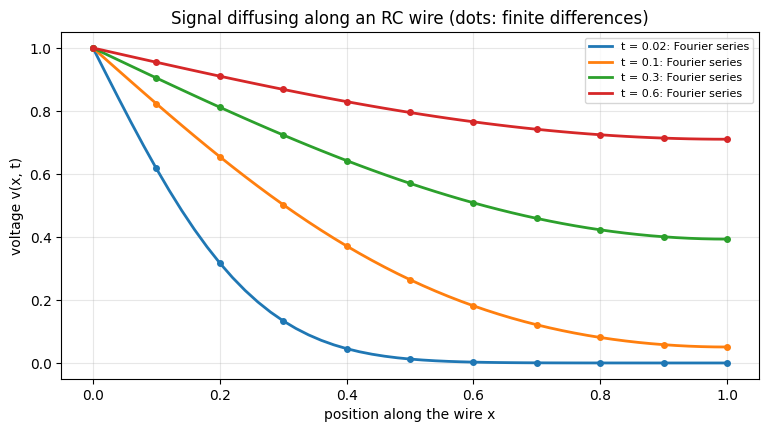

In [20]:
def v_series(x_, t_, n_terms=200):
    total = np.ones(np.broadcast(x_, t_).shape)
    for n in range(1, n_terms + 1):
        lam_n = (2 * n - 1) * np.pi / 2
        total -= 4 / ((2 * n - 1) * np.pi) * np.sin(lam_n * x_) * np.exp(-lam_n ** 2 * t_)
    return total

# Explicit finite-difference solution for comparison
nx = 51
xg = np.linspace(0, 1, nx)
dx = xg[1] - xg[0]
dt_fd = 0.4 * dx ** 2                       # stable because dt/dx² ≤ 1/2
snap_times = [0.02, 0.1, 0.3, 0.6]
vg = np.zeros(nx)
vg[0] = 1.0
snaps, step = {}, 0
for t_target in snap_times:
    while step * dt_fd < t_target - 1e-12:
        lap = np.zeros(nx)
        lap[1:-1] = vg[:-2] - 2 * vg[1:-1] + vg[2:]
        lap[-1] = 2 * vg[-2] - 2 * vg[-1]   # ghost node for the open end
        vg = vg + dt_fd / dx ** 2 * lap
        vg[0] = 1.0
        step += 1
    snaps[t_target] = (step * dt_fd, vg.copy())

plt.figure(figsize=(9, 4.5))
for t_target, (t_actual, profile) in snaps.items():
    exact_profile = v_series(xg, t_actual)
    plt.plot(xg, exact_profile, lw=2, label=f"t = {t_target}: Fourier series")
    plt.plot(xg[::5], profile[::5], "o", ms=4, color=plt.gca().lines[-1].get_color())
    print(f"t = {t_target}: max |series - finite differences| = {np.max(np.abs(exact_profile - profile)):.2e}")
plt.xlabel("position along the wire x")
plt.ylabel("voltage v(x, t)")
plt.title("Signal diffusing along an RC wire (dots: finite differences)")
plt.legend(fontsize=8)
plt.show()

Far end reaches 50 % at scaled time t* = 0.3787  ->  real delay = 0.3787 · r c L²
Delay grows with the SQUARE of the length: doubling a wire quadruples its delay.

wire length  0.5 mm  ->  50 % delay     1.89 ps
wire length  1.0 mm  ->  50 % delay     7.57 ps
wire length  2.0 mm  ->  50 % delay    30.30 ps
wire length  3.0 mm  ->  50 % delay    68.17 ps
wire length  5.0 mm  ->  50 % delay   189.37 ps


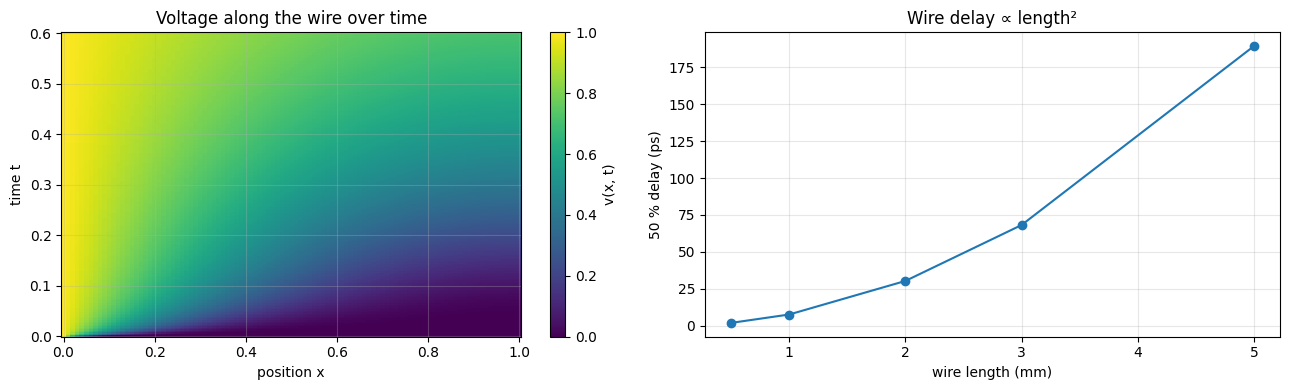

In [21]:
t50 = brentq(lambda t_: float(v_series(1.0, t_)) - 0.5, 1e-4, 5)
print(f"Far end reaches 50 % at scaled time t* = {t50:.4f}  ->  real delay = {t50:.4f} · r c L²")
print("Delay grows with the SQUARE of the length: doubling a wire quadruples its delay.\n")

r_wire, c_wire = 1e5, 2e-10                # typical on-chip wire: 0.1 Ω/µm and 0.2 fF/µm
lengths_mm = np.array([0.5, 1, 2, 3, 5])
delays_ps = t50 * r_wire * c_wire * (lengths_mm * 1e-3) ** 2 * 1e12
for Lm, d in zip(lengths_mm, delays_ps):
    print(f"wire length {Lm:4.1f} mm  ->  50 % delay {d:8.2f} ps")

X_, T_ = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0.001, 0.6, 200))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
im = axs[0].pcolormesh(X_, T_, v_series(X_, T_), shading="auto", cmap="viridis")
fig.colorbar(im, ax=axs[0], label="v(x, t)")
axs[0].set(xlabel="position x", ylabel="time t", title="Voltage along the wire over time")
axs[1].plot(lengths_mm, delays_ps, "o-")
axs[1].set(xlabel="wire length (mm)", ylabel="50 % delay (ps)", title="Wire delay ∝ length²")
plt.tight_layout()
plt.show()

### 9.3 A lossless transmission line: the wave equation
At high frequencies, the cable's inductance $\ell$ and capacitance $c$ per unit length dominate, and the voltage obeys the **wave equation**
$$\frac{\partial^2 v}{\partial t^2} = \frac{1}{\ell c}\,\frac{\partial^2 v}{\partial x^2},$$
so signals travel at speed $1/\sqrt{\ell c}$. On a line of length 1 with both ends **shorted** ($v = 0$), a pulse launched in the middle splits into two halves. They reflect from the ends **inverted**. The Fourier series solution is
$$v(x,t) = \sum_n b_n \sin(n\pi x)\cos(n\pi t), \qquad b_n = 2\int_0^1 f(x)\sin(n\pi x)\,dx,$$
which matches **d'Alembert's** travelling-wave solution $v = \tfrac12[F(x-t) + F(x+t)]$.

t = 0.0: max |series - d'Alembert| = 2.31e-15
t = 0.15: max |series - d'Alembert| = 1.49e-15
t = 0.4: max |series - d'Alembert| = 1.46e-15
t = 0.6: max |series - d'Alembert| = 3.11e-15
t = 1.0: max |series - d'Alembert| = 3.66e-15


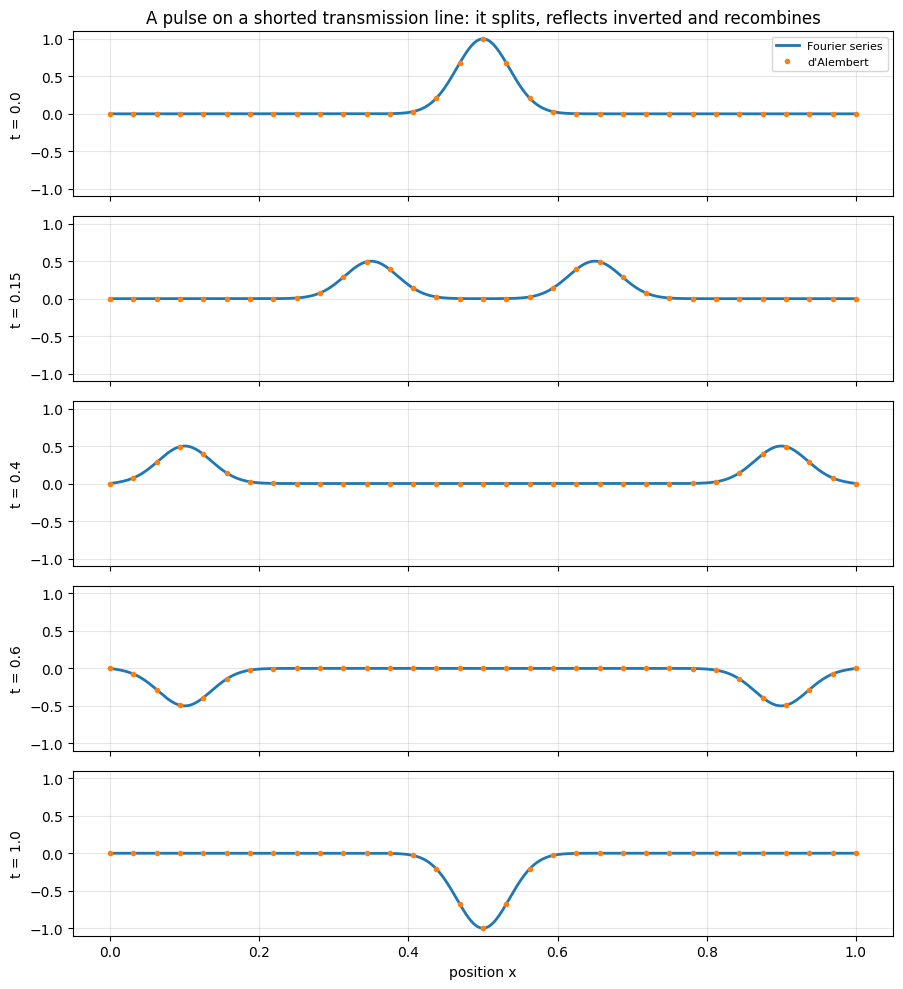

In [22]:
xw = np.linspace(0, 1, 801)
f0 = np.exp(-((xw - 0.5) / 0.05) ** 2)                 # initial pulse, zero initial velocity
n_modes = np.arange(1, 151)
b = np.array([2 * trapezoid(f0 * np.sin(n * np.pi * xw), xw) for n in n_modes])

def wave_series(t_):
    return (b[:, None] * np.sin(np.outer(n_modes, np.pi * xw)) * np.cos(n_modes * np.pi * t_)[:, None]).sum(axis=0)

def odd_periodic(z):
    z = np.mod(z, 2.0)
    return np.where(z <= 1, np.interp(z, xw, f0), -np.interp(2 - z, xw, f0))

def dalembert(t_):
    return 0.5 * (odd_periodic(xw - t_) + odd_periodic(xw + t_))

fig, axs = plt.subplots(5, 1, figsize=(9, 10), sharex=True)
for ax, t_snap in zip(axs, [0.0, 0.15, 0.4, 0.6, 1.0]):
    ax.plot(xw, wave_series(t_snap), lw=2, label="Fourier series")
    ax.plot(xw[::25], dalembert(t_snap)[::25], "o", ms=3, label="d'Alembert")
    ax.set(ylim=(-1.1, 1.1), ylabel=f"t = {t_snap}")
    print(f"t = {t_snap}: max |series - d'Alembert| = {np.max(np.abs(wave_series(t_snap) - dalembert(t_snap))):.2e}")
axs[0].legend(loc="upper right", fontsize=8)
axs[0].set_title("A pulse on a shorted transmission line: it splits, reflects inverted and recombines")
axs[-1].set_xlabel("position x")
plt.tight_layout()
plt.show()

## 10. Results summary and conclusion

In [23]:
summary = {
    "RC time constant (ms)": f"{TAU*1e3:.2f}",
    "RLC critical resistance (Ω, normalised)": f"{2*np.sqrt(5):.3f}",
    "RLC poles (R = 2 Ω)": str(poles),
    "Two-stage vs one-stage roll-off (dB/decade)": f"{slope2:.1f} vs {slope1:.1f}",
    "Tuned filter (3 kHz) quality factor Q": f"{Q_BP:.1f}",
    "Square-wave power in the fundamental": f"{100*8/np.pi**2:.1f} %",
    "Noise filter hum attenuation at 50 Hz (dB)": f"{20*np.log10(abs(H_lp(50))):.1f}",
    "SNR before / after filtering (dB)": f"{snr_db(clean, noisy - clean):.1f} / {snr_db(ref_freq, out_freq - ref_freq):.1f}",
    "Leaky cable far-end voltage (V)": f"{V_exact[-1]:.2f} of {V_IN:.0f}",
    "RC wire 50 % delay (scaled)": f"{t50:.4f} · r c L²",
}
for key, val in summary.items():
    print(f"{key:45s} {val}")

RC time constant (ms)                         1.00
RLC critical resistance (Ω, normalised)       4.472
RLC poles (R = 2 Ω)                           [-1 - 2*I, -1 + 2*I]
Two-stage vs one-stage roll-off (dB/decade)   -40.0 vs -20.0
Tuned filter (3 kHz) quality factor Q         9.4
Square-wave power in the fundamental          81.1 %
Noise filter hum attenuation at 50 Hz (dB)    -16.0
SNR before / after filtering (dB)             0.5 / 16.4
Leaky cable far-end voltage (V)               26.58 of 100
RC wire 50 % delay (scaled)                   0.3787 · r c L²


### Conclusion
This project modelled the complete front end of a sensor measurement system with differential equations and used every topic from SENG 202:

* **First-order ODEs** (integrating factor) described how an RC filter switches on and how it scales and delays a sine wave.
* **Second-order ODEs** explained overdamped, critically damped and underdamped behaviour, and **undetermined coefficients** revealed resonance.
* **Initial-value problems** were solved exactly with SymPy and confirmed numerically every time.
* **Laplace transforms** handled initial conditions, switches, pulses and impulses. They gave the transfer function and poles, and the convolution theorem predicted the response to any input.
* **Systems of ODEs** and their eigenvalues produced phase portraits, and showed why a two-stage filter rolls off twice as fast.
* A **series solution** handled a circuit with a time-varying capacitor, where constant-coefficient methods fail, and matched the exact Airy-function solution.
* **Fourier series** broke the clock interference into harmonics, showed the Gibbs phenomenon and Parseval's identity, and explained how a tuned RLC filter extracts one harmonic.
* The **Fourier transform** revealed the signal, hum and noise in the spectrum, guided the design of a Butterworth filter, and linked back to the Laplace transform.
* **Boundary-value problems** and **PDEs** described the cable: voltage loss on a leaky line, diffusion delay that grows with length², and pulse reflections on a transmission line.

### Possible extensions
* Use real recorded sensor data (for example, an uploaded `.csv`) instead of a synthetic signal.
* Add a non-linear component (a diode) and solve the resulting non-linear ODE numerically.
* Model the full telegrapher's equations, with both resistance and inductance, for a realistic cable.